# House Price Prediction — End-to-End Machine Learning

This notebook walks through a complete regression workflow on the Kaggle **House Prices: Advanced Regression Techniques** dataset: understanding the data, checking its quality, exploring it, cleaning it, engineering features, training six regression models, comparing them, and saving the best one.

The goal is not only a good score. The goal is a workflow where every decision can be explained and defended: why a missing value was filled a certain way, why the target is log-transformed, why one model generalises better than another.


In [41]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from IPython.display import Image

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_raw_data
from src.data_cleaning import (
    clean_data,
    remove_price_outliers,
    STRUCTURAL_CATEGORICAL_NA,
)
from src.feature_engineering import engineer_features
from src.preprocessing import make_pipeline, split_feature_types
from src.train import (
    RANDOM_STATE,
    compare_models,
    get_models,
    prepare_training_data,
    split_data,
    train_final_model,
)
from src.evaluation import (
    predict_prices,
    regression_metrics,
    plot_actual_vs_predicted,
    plot_model_comparison,
    plot_residual_distribution,
    plot_residuals_vs_predicted,
)
from src.predict import load_model, predict

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 100)

IMAGES_DIR = PROJECT_ROOT / "images"
IMAGES_DIR.mkdir(exist_ok=True)
RANDOM_STATE

42

In [42]:
train, test = load_raw_data()

print(f"Training rows: {train.shape[0]:,} | columns: {train.shape[1]}")
print(f"Test rows:     {test.shape[0]:,} | columns: {test.shape[1]}")
print(f"Target present in test set: {'SalePrice' in test.columns}")
train.head(3)

Training rows: 1,460 | columns: 81
Test rows:     1,459 | columns: 80
Target present in test set: False


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


In [43]:
train.tail(3)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,9,1941,2006,Gable,CompShg,CemntBd,CmentBd,NaN,0.0,Ex,Gd,Stone,TA,Gd,No,GLQ,275,Unf,0,877,1152,GasA,Ex,Y,SBrkr,1188,1152,0,2340,0,0,2,0,4,1,Gd,9,Typ,2,Gd,Attchd,1941.0,RFn,1,252,TA,TA,Y,0,60,0,0,0,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,5,6,1950,1996,Hip,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,TA,TA,Mn,GLQ,49,Rec,1029,0,1078,GasA,Gd,Y,FuseA,1078,0,0,1078,1,0,1,0,2,1,Gd,5,Typ,0,NaN,Attchd,1950.0,Unf,1,240,TA,TA,Y,366,0,112,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Edwards,Norm,Norm,1Fam,1Story,5,6,1965,1965,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,Gd,TA,CBlock,TA,TA,No,BLQ,830,LwQ,290,136,1256,GasA,Gd,Y,SBrkr,1256,0,0,1256,1,0,1,1,3,1,TA,6,Typ,0,NaN,Attchd,1965.0,Fin,1,276,TA,TA,Y,736,68,0,0,0,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [44]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [45]:
print("Column types:")
print(train.dtypes.value_counts())

key_numeric = ["SalePrice", "GrLivArea", "LotArea", "TotalBsmtSF", "OverallQual", "YearBuilt"]
train[key_numeric].describe().T.round(1)

Column types:
object     43
int64      35
float64     3
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.2,79442.5,34900.0,129975.0,163000.0,214000.0,755000.0
GrLivArea,1460.0,1515.5,525.5,334.0,1129.5,1464.0,1776.8,5642.0
LotArea,1460.0,10516.8,9981.3,1300.0,7553.5,9478.5,11601.5,215245.0
TotalBsmtSF,1460.0,1057.4,438.7,0.0,795.8,991.5,1298.2,6110.0
OverallQual,1460.0,6.1,1.4,1.0,5.0,6.0,7.0,10.0
YearBuilt,1460.0,1971.3,30.2,1872.0,1954.0,1973.0,2000.0,2010.0


In [46]:
categorical_cols = train.select_dtypes(include="object").columns
cardinality = train[categorical_cols].nunique().sort_values(ascending=False)
print(f"Categorical features: {len(categorical_cols)}")
cardinality.head(12).to_frame("distinct_values")

Categorical features: 43


,distinct_values
Neighborhood,25
Exterior2nd,16
Exterior1st,15
SaleType,9
Condition1,9
Condition2,8
HouseStyle,8
RoofMatl,8
Functional,7
BsmtFinType2,6


In [47]:
print(f"SalePrice skewness:          {train['SalePrice'].skew():.2f}")
print(f"SalePrice skew after log1p:  {np.log1p(train['SalePrice']).skew():.2f}")
print(f"Mean:   ${train['SalePrice'].mean():,.0f}")
print(f"Median: ${train['SalePrice'].median():,.0f}")

SalePrice skewness:          1.88
SalePrice skew after log1p:  0.12
Mean:   $180,921
Median: $163,000


## 4. Data quality assessment

We check six things: missing values, duplicates, data types, unexpected values, high-cardinality categories, and outliers.

### Missing values

Many columns are complete; a smaller group is mostly empty. The important question is **why** a value is missing, because "not recorded" and "does not exist" require different treatment.

In [48]:
missing = pd.DataFrame({
    "missing": train.isna().sum(),
    "percent": train.isna().mean() * 100,
})
missing = missing[missing["missing"] > 0].sort_values("missing", ascending=False)
missing.round(2).head(20)

,missing,percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


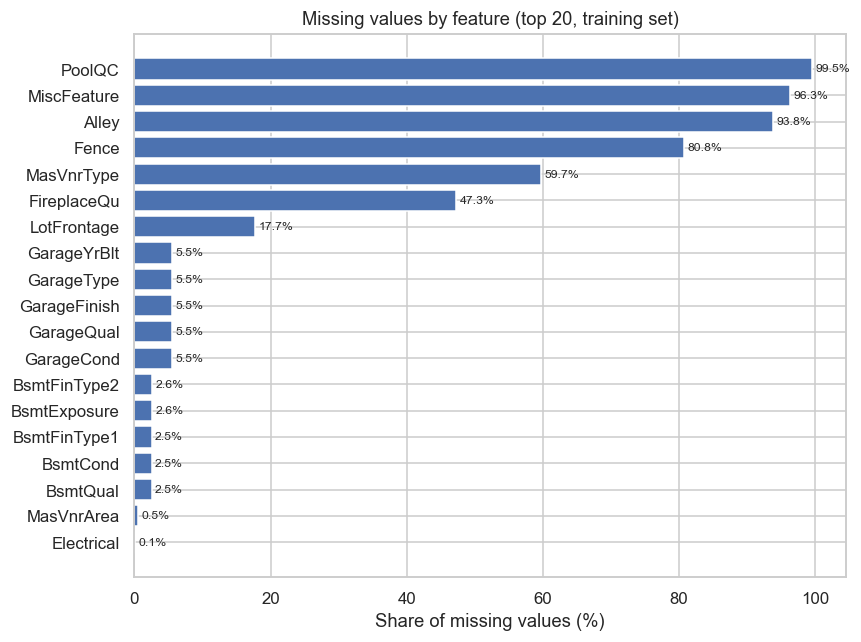

In [49]:
plot_data = missing.head(20).sort_values("missing")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(plot_data.index, plot_data["percent"], color="#4C72B0")
ax.set_xlabel("Share of missing values (%)")
ax.set_title("Missing values by feature (top 20, training set)")
for position, value in enumerate(plot_data["percent"]):
    ax.text(value + 0.5, position, f"{value:.1f}%", va="center", fontsize=8)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "quality_missing_values.png", dpi=130)
plt.show()

In [50]:
checks = pd.DataFrame(
    {
        "missing_rows": [
            train["PoolQC"].isna().sum(),
            train["GarageType"].isna().sum(),
            train["BsmtQual"].isna().sum(),
            train["FireplaceQu"].isna().sum(),
        ],
        "supporting_evidence": [
            f"PoolArea is 0 for {(train.loc[train.PoolQC.isna(), 'PoolArea'] == 0).mean():.0%} of these rows",
            f"GarageArea is also missing for {train.loc[train.GarageType.isna(), 'GarageArea'].isna().mean():.0%} of these rows",
            f"TotalBsmtSF is also missing for {train.loc[train.BsmtQual.isna(), 'TotalBsmtSF'].isna().mean():.0%} of these rows",
            f"Fireplaces is 0 for {(train.loc[train.FireplaceQu.isna(), 'Fireplaces'] == 0).mean():.0%} of these rows",
        ],
    },
    index=["PoolQC", "GarageType", "BsmtQual", "FireplaceQu"],
)
checks.index.name = "feature"
checks

,missing_rows,supporting_evidence
feature,,
PoolQC,1453,PoolArea is 0 for 100% of these rows
GarageType,81,GarageArea is also missing for 0% of these rows
BsmtQual,37,TotalBsmtSF is also missing for 0% of these rows
FireplaceQu,690,Fireplaces is 0 for 100% of these rows


In [51]:
print(f"Duplicate rows: {train.duplicated().sum()}")
print(f"Duplicate Ids:  {train['Id'].duplicated().sum()}")
print(f"LotFrontage missing: {train['LotFrontage'].isna().sum()} rows ({train['LotFrontage'].isna().mean():.1%})")

print("\nMedian LotFrontage by neighborhood (top 5):")
train.groupby("Neighborhood")["LotFrontage"].median().sort_values(ascending=False).head(5).to_frame("median_frontage")

Duplicate rows: 0
Duplicate Ids:  0
LotFrontage missing: 259 rows (17.7%)

Median LotFrontage by neighborhood (top 5):


,median_frontage
Neighborhood,
NoRidge,91.0
NridgHt,88.5
Timber,85.0
ClearCr,80.0
NWAmes,80.0


No duplicate rows or IDs exist, so there is nothing to remove there.

### Unexpected values and outliers

The extreme `GrLivArea` values deserve a look before modelling. A scatter plot in the next section shows the full picture; here are the largest houses.

In [52]:
train.loc[train["GrLivArea"] > 4000, ["Id", "Neighborhood", "GrLivArea", "OverallQual", "SalePrice"]].sort_values("GrLivArea")

,Id,Neighborhood,GrLivArea,OverallQual,SalePrice
691,692,NoRidge,4316,10,755000
1182,1183,NoRidge,4476,10,745000
523,524,Edwards,4676,10,184750
1298,1299,Edwards,5642,10,160000


## 5. Exploratory Data Analysis

Each chart below is saved in `images/` and followed by a short interpretation. The purpose is to understand relationships before choosing features and models, not to prove causation.

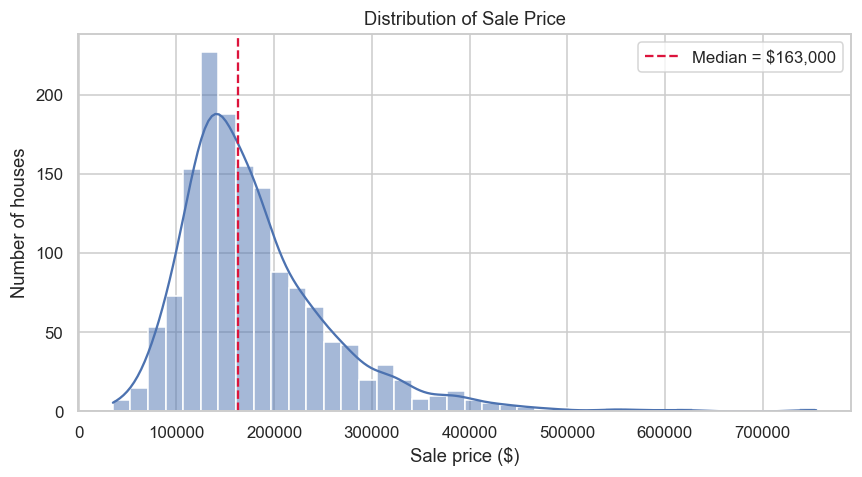

In [53]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(train["SalePrice"], bins=40, kde=True, ax=ax)
ax.axvline(train["SalePrice"].median(), color="crimson", linestyle="--", label=f"Median = ${train['SalePrice'].median():,.0f}")
ax.set_title("Distribution of Sale Price")
ax.set_xlabel("Sale price ($)")
ax.set_ylabel("Number of houses")
ax.legend()
fig.tight_layout()
fig.savefig(IMAGES_DIR / "01_saleprice_distribution.png", dpi=130)
plt.show()

**Reading the chart.** Most sales cluster between roughly $100k and $250k, with a long tail beyond $400k. The distribution is unimodal but asymmetric, which is why a symmetric model like linear regression sees the expensive tail as a handful of high-leverage points.

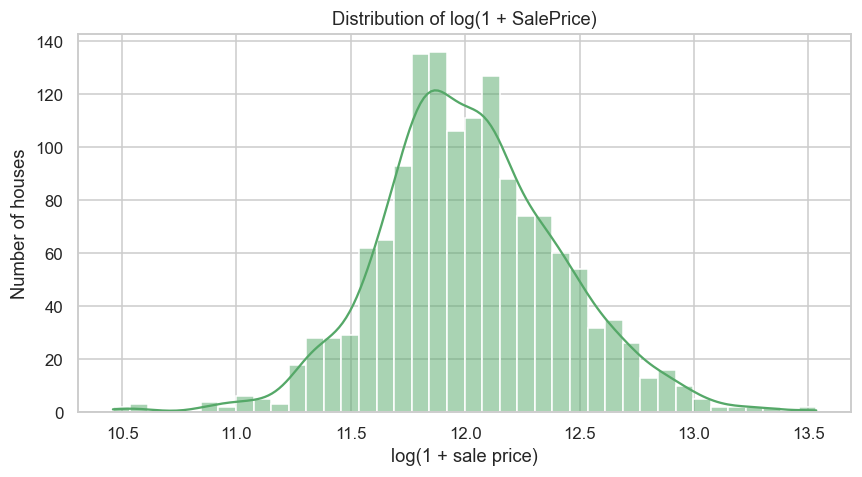

In [54]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(np.log1p(train["SalePrice"]), bins=40, kde=True, ax=ax, color="#55A868")
ax.set_title("Distribution of log(1 + SalePrice)")
ax.set_xlabel("log(1 + sale price)")
ax.set_ylabel("Number of houses")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "02_saleprice_log_distribution.png", dpi=130)
plt.show()

After the log transform the shape is close to a normal distribution. This matches the lower skewness reported earlier and supports training on the log scale.

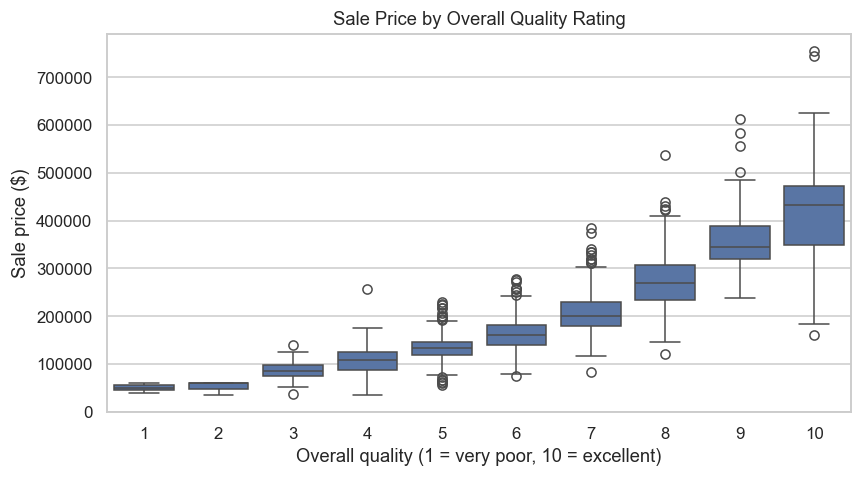

In [55]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=train, x="OverallQual", y="SalePrice", ax=ax, color="#4C72B0")
ax.set_title("Sale Price by Overall Quality Rating")
ax.set_xlabel("Overall quality (1 = very poor, 10 = excellent)")
ax.set_ylabel("Sale price ($)")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "03_overallqual_vs_saleprice.png", dpi=130)
plt.show()

**Reading the chart.** Median price rises steadily with quality, and the spread widens too. The ordering is monotonic, which makes `OverallQual` one of the strongest single predictors. Because the rating is ordinal and coarse (10 levels), its relationship with price is closer to a step function than a straight line; tree models can capture that naturally, linear models need the one-hot representation.

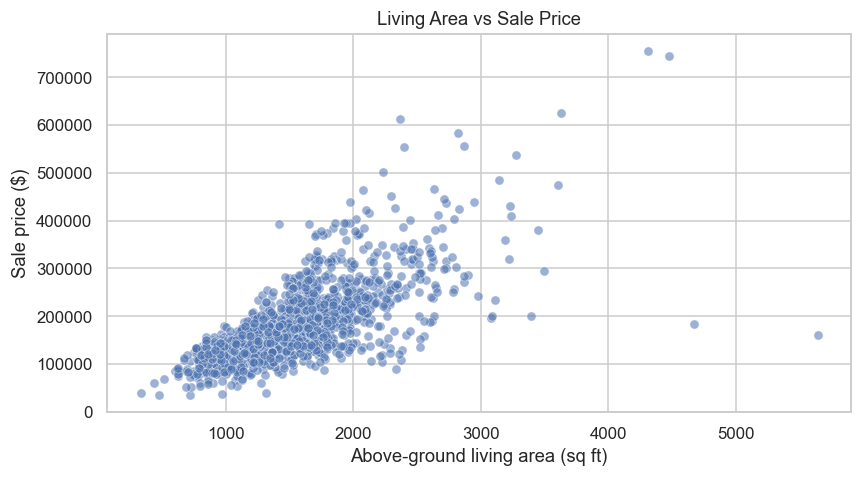

In [56]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=train, x="GrLivArea", y="SalePrice", alpha=0.55, ax=ax)
ax.set_title("Living Area vs Sale Price")
ax.set_xlabel("Above-ground living area (sq ft)")
ax.set_ylabel("Sale price ($)")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "04_grlivarea_vs_saleprice.png", dpi=130)
plt.show()

**Reading the chart.** Price increases with living area, but the relationship is not a tight straight line: at the same size, prices vary by a factor of two or more. The two very large but cheap houses sit far below the main cloud and are the outliers discussed above.

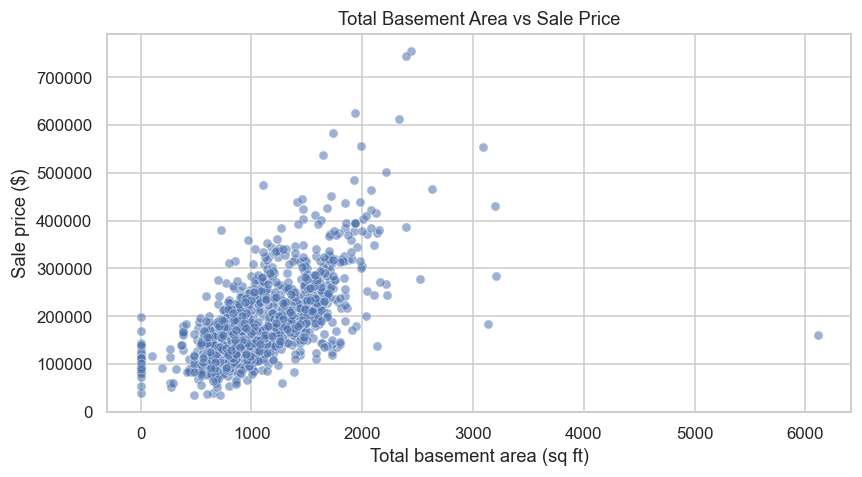

In [57]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=train, x="TotalBsmtSF", y="SalePrice", alpha=0.55, ax=ax)
ax.set_title("Total Basement Area vs Sale Price")
ax.set_xlabel("Total basement area (sq ft)")
ax.set_ylabel("Sale price ($)")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "05_totalbsmtsf_vs_saleprice.png", dpi=130)
plt.show()

**Reading the chart.** Basement area is positively related to price, but a large vertical stack of points at zero means "no basement" — a genuinely different type of house, not a missing measurement. That column is effectively a mix of a size variable and a presence flag, which is one reason `TotalSF` is later engineered.

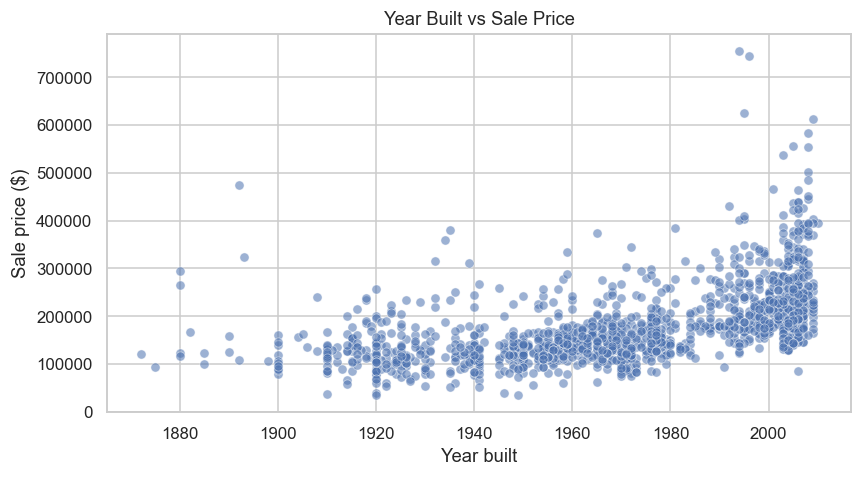

In [58]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=train, x="YearBuilt", y="SalePrice", alpha=0.55, ax=ax)
ax.set_title("Year Built vs Sale Price")
ax.set_xlabel("Year built")
ax.set_ylabel("Sale price ($)")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "06_yearbuilt_vs_saleprice.png", dpi=130)
plt.show()

**Reading the chart.** Newer houses tend to sell for more, but the pattern is noisy and clearly influenced by other factors (neighborhood, renovation, size). This is an association in this dataset; it is not evidence that building later causes a higher price.

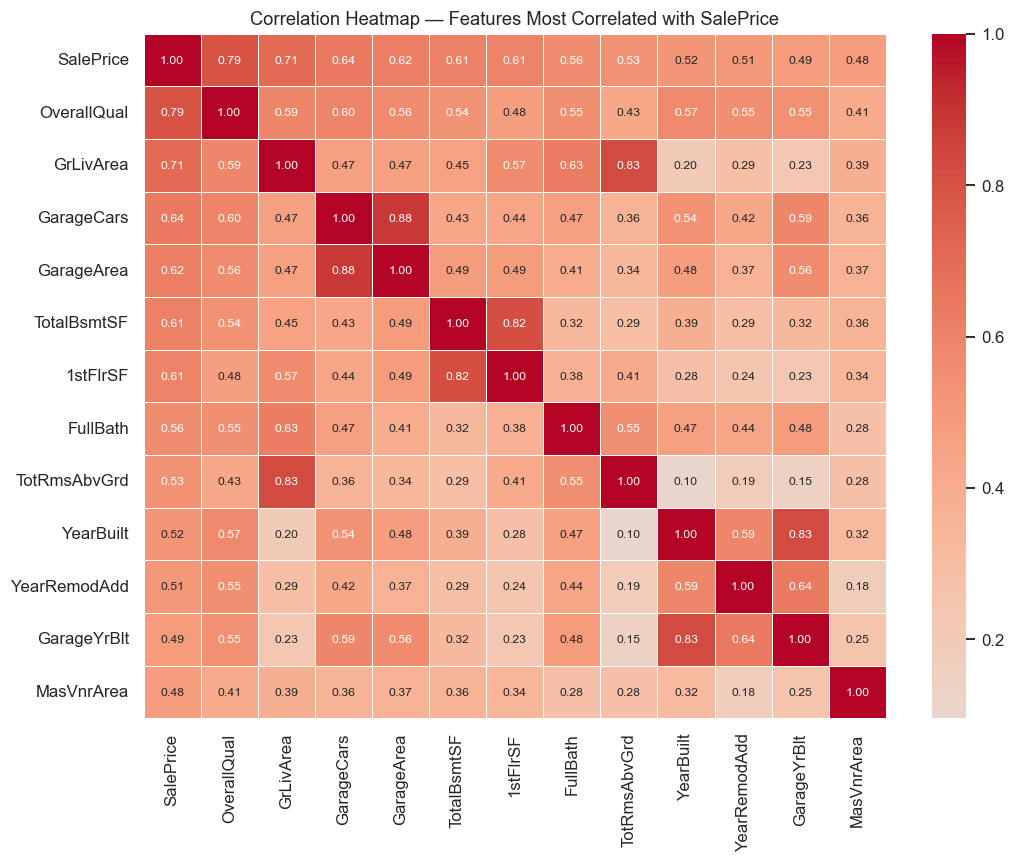

In [59]:
numeric = train.select_dtypes(include="number")
corr = numeric.corr()
top_features = corr["SalePrice"].abs().sort_values(ascending=False).head(13).index

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr.loc[top_features, top_features], annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation Heatmap — Features Most Correlated with SalePrice")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "07_correlation_heatmap.png", dpi=130)
plt.show()

**Reading the chart.** `OverallQual`, `GrLivArea`, `GarageCars`, `GarageArea`, `TotalBsmtSF` and `1stFlrSF` correlate most strongly with price. Notice also that these size variables correlate strongly **with each other**. That redundancy (multicollinearity) makes plain linear coefficients unstable, which is exactly what Ridge and Lasso regularisation is designed to handle.

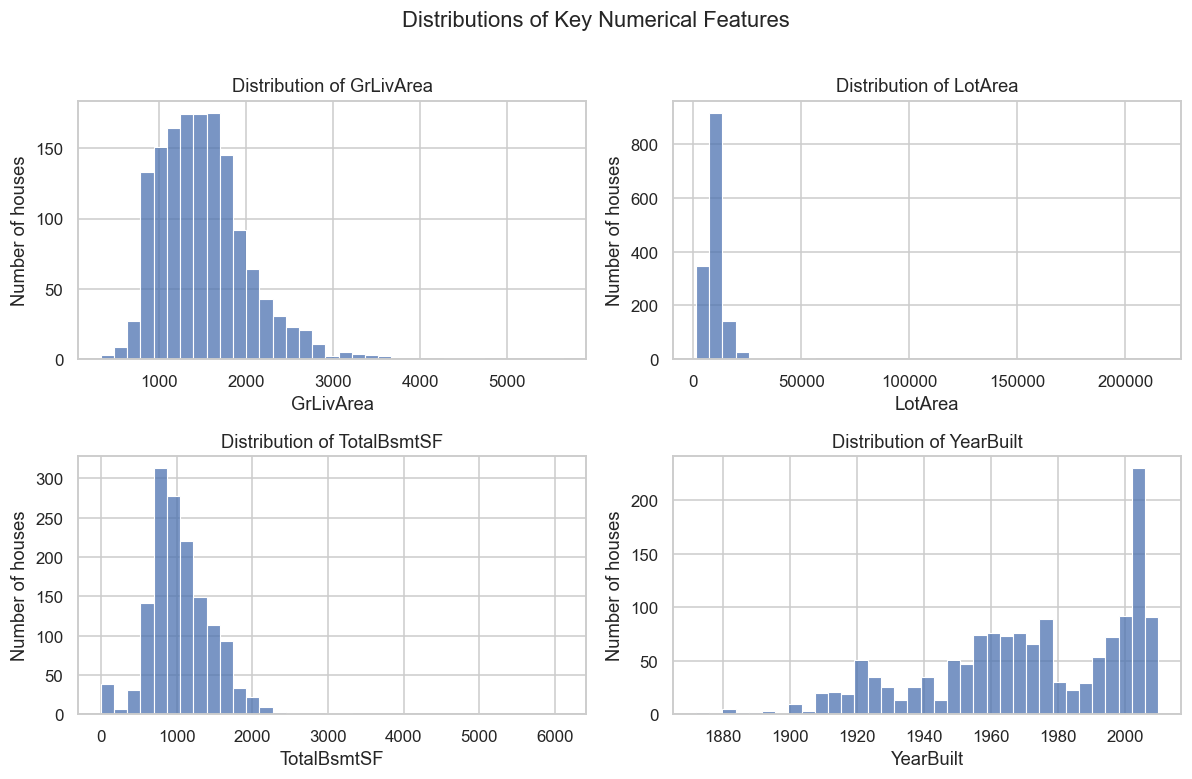

In [60]:
plot_columns = ["GrLivArea", "LotArea", "TotalBsmtSF", "YearBuilt"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, column in zip(axes.ravel(), plot_columns):
    sns.histplot(train[column], bins=35, ax=ax, color="#4C72B0")
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of houses")
fig.suptitle("Distributions of Key Numerical Features", y=1.01)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "08_numeric_distributions.png", dpi=130, bbox_inches="tight")
plt.show()

**Reading the charts.** Living area and lot area are right-skewed with long tails; many houses have no basement (the spike at zero); construction years are spread over more than a century with most houses built after 1950. These shapes argue for robust handling (median imputation, tree models) and for looking at residuals rather than assuming normal errors.

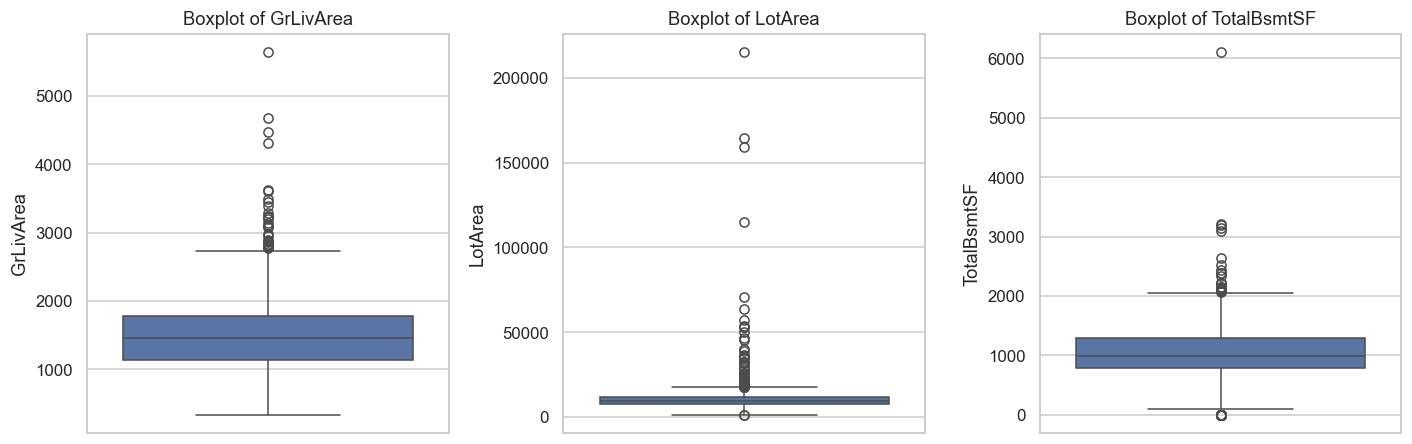

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, column in zip(axes, ["GrLivArea", "LotArea", "TotalBsmtSF"]):
    sns.boxplot(y=train[column], ax=ax, color="#4C72B0")
    ax.set_title(f"Boxplot of {column}")
    ax.set_ylabel(column)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "09_selected_boxplots.png", dpi=130)
plt.show()

**Reading the charts.** Boxplots make the one-sided tails explicit: a handful of houses have very large lot or living areas. Only the two suspicious low-price large houses are removed, because size alone is a legitimate reason for a high price.

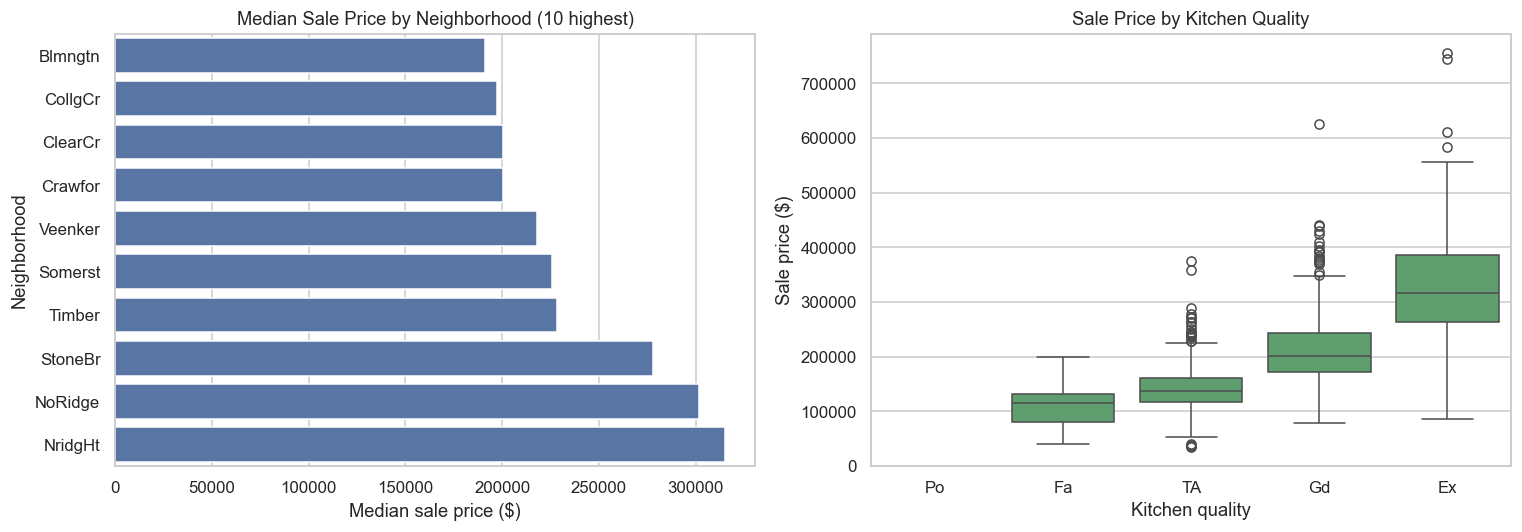

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

neighborhood_price = train.groupby("Neighborhood")["SalePrice"].median().sort_values().tail(10)
sns.barplot(x=neighborhood_price.values, y=neighborhood_price.index, ax=axes[0], color="#4C72B0")
axes[0].set_title("Median Sale Price by Neighborhood (10 highest)")
axes[0].set_xlabel("Median sale price ($)")
axes[0].set_ylabel("Neighborhood")

sns.boxplot(data=train, x="KitchenQual", y="SalePrice", ax=axes[1], order=["Po", "Fa", "TA", "Gd", "Ex"], color="#55A868")
axes[1].set_title("Sale Price by Kitchen Quality")
axes[1].set_xlabel("Kitchen quality")
axes[1].set_ylabel("Sale price ($)")

fig.tight_layout()
fig.savefig(IMAGES_DIR / "10_categorical_comparisons.png", dpi=130)
plt.show()

**Reading the charts.** Location matters: the top neighborhoods have median prices several times higher than the cheapest ones. Kitchen quality shows an ordered relationship with price, so one-hot encoding ordered categories is acceptable here — the model can learn a separate effect per level.

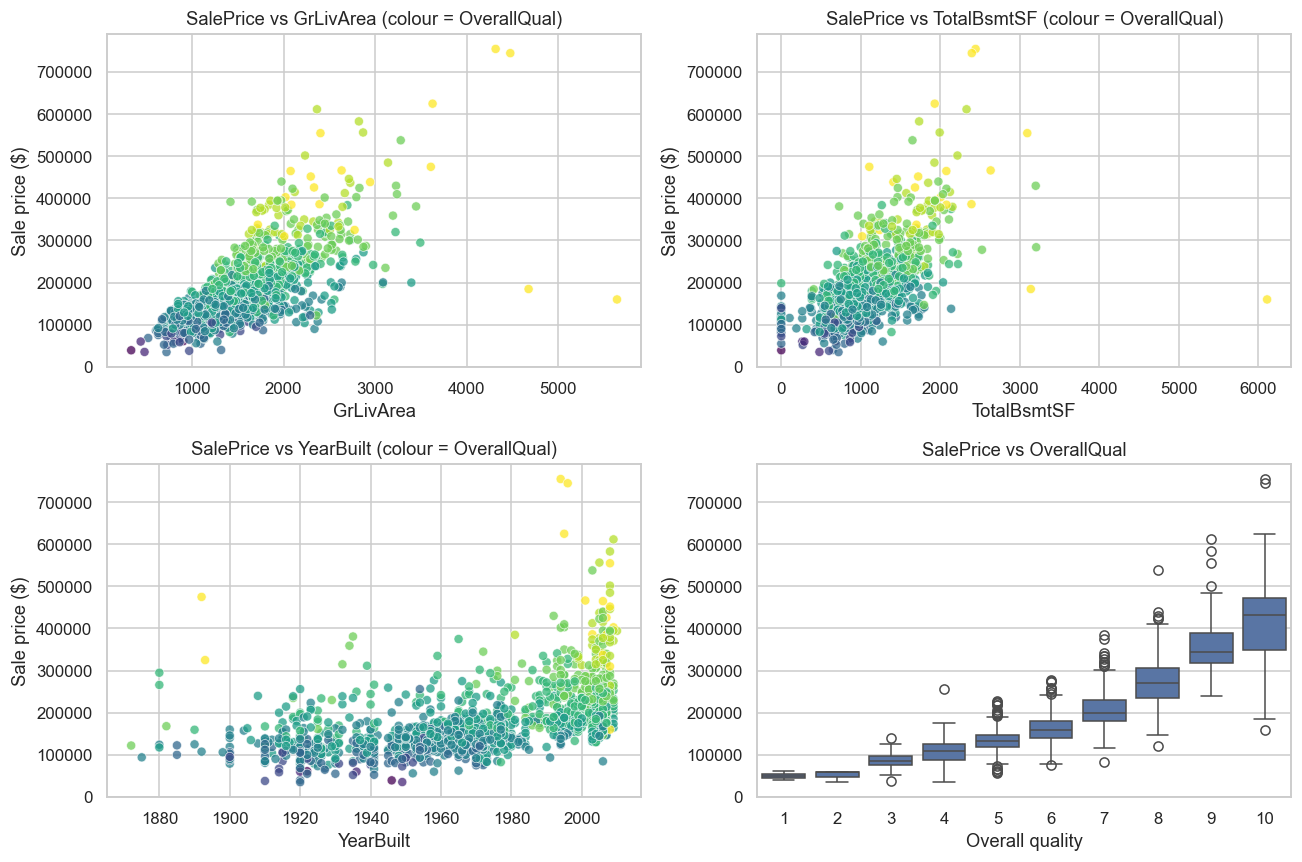

In [63]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column in zip(axes.ravel()[:3], ["GrLivArea", "TotalBsmtSF", "YearBuilt"]):
    sns.scatterplot(data=train, x=column, y="SalePrice", hue="OverallQual", palette="viridis", alpha=0.75, legend=False, ax=ax)
    ax.set_title(f"SalePrice vs {column} (colour = OverallQual)")
    ax.set_xlabel(column)
    ax.set_ylabel("Sale price ($)")

sns.boxplot(data=train, x="OverallQual", y="SalePrice", ax=axes.ravel()[3], color="#4C72B0")
axes.ravel()[3].set_title("SalePrice vs OverallQual")
axes.ravel()[3].set_xlabel("Overall quality")
axes.ravel()[3].set_ylabel("Sale price ($)")

fig.tight_layout()
fig.savefig(IMAGES_DIR / "11_saleprice_vs_important.png", dpi=130)
plt.show()

**Reading the charts.** Colour adds a third dimension: at a given size, higher quality generally means a higher price. Price is not a simple function of any single feature — which is why a multivariate model is needed and why residuals will still be substantial.

### EDA takeaways

- Price is right-skewed; modelling `log1p(SalePrice)` is a justified choice that will be checked against dollar-scale metrics.
- Quality, size and location are the dominant associations.
- Size features overlap heavily, so regularised linear models are a sensible baseline.
- Basement and garage columns mix presence with quantity, which motivates combined features.
- A couple of unusual large-and-cheap sales should be removed from training only.

## 6. Data cleaning

The cleaning rules live in `src/data_cleaning.py` so the notebook, training script and prediction function all use exactly the same logic. Here we verify the effect of each rule.

In [64]:
cleaned = clean_data(train)

comparison = pd.DataFrame({
    "before": train.isna().sum(),
    "after": cleaned.isna().sum(),
})
comparison = comparison[(comparison["before"] > 0) | (comparison["after"] > 0)]
comparison = comparison.sort_values("before", ascending=False)
comparison.round(1).head(20)

,before,after
PoolQC,1453,0
MiscFeature,1406,0
Alley,1369,0
Fence,1179,0
MasVnrType,872,0
FireplaceQu,690,0
LotFrontage,259,0
GarageType,81,0
GarageYrBlt,81,0
GarageFinish,81,0


In [65]:
example = cleaned.loc[cleaned["GarageType"] == "None", ["GarageType", "GarageArea", "GarageCars", "GarageYrBlt", "YearBuilt"]].head(3)
print("Example rows where the house has no garage:")
example

Example rows where the house has no garage:


,GarageType,GarageArea,GarageCars,GarageYrBlt,YearBuilt
39,None,0,0,1955.0,1955
48,None,0,0,1920.0,1920
78,None,0,0,1968.0,1968


In [66]:
outlier_rows = train[(train["GrLivArea"] > 4000) & (train["SalePrice"] < 300_000)]
print(f"Rows removed as training outliers: {len(outlier_rows)} of {len(train)}")
outlier_rows[["Id", "GrLivArea", "SalePrice", "OverallQual", "Neighborhood"]]

Rows removed as training outliers: 2 of 1460


,Id,GrLivArea,SalePrice,OverallQual,Neighborhood
523,524,4676,184750,10,Edwards
1298,1299,5642,160000,10,Edwards


In [67]:
engineered = engineer_features(clean_data(train, remove_outliers=True))
new_features = ["TotalSF", "TotalBathrooms", "HouseAge", "RemodeledAge", "TotalPorchSF"]

engineered[new_features].head()

,TotalSF,TotalBathrooms,HouseAge,RemodeledAge,TotalPorchSF
0,2566,3.5,5,5,61
1,2524,2.5,31,31,298
2,2706,3.5,7,6,42
3,2473,2.0,91,36,307
4,3343,3.5,8,8,276


In [68]:
engineered[new_features + ["SalePrice"]].corr()["SalePrice"].sort_values(ascending=False).round(3).to_frame("correlation_with_SalePrice")

,correlation_with_SalePrice
SalePrice,1.000
TotalSF,0.833
TotalBathrooms,0.636
TotalPorchSF,0.393
RemodeledAge,-0.510
HouseAge,-0.524


In [69]:
X, y = prepare_training_data(train, remove_outliers=True)
X_train, X_val, y_train, y_val = split_data(X, y)

print(f"Features incl. Id: {X.shape[1]}")
print(f"Training rows: {len(X_train)} | validation rows: {len(X_val)}")
print(f"Median price — train: ${y_train.median():,.0f} | validation: ${y_val.median():,.0f}")

numeric_features, categorical_features = split_feature_types(X_train)
print(f"Numeric features: {len(numeric_features)} | categorical features: {len(categorical_features)}")

Features incl. Id: 85
Training rows: 1166 | validation rows: 292
Median price — train: $162,250 | validation: $167,050
Numeric features: 40 | categorical features: 44


In [70]:
example_pipeline = make_pipeline(get_models()["Linear Regression"][0], X_train)
example_pipeline

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [71]:
results, fitted_models = compare_models(X_train, y_train, X_val, y_val)
results_sorted = results.sort_values("val_rmse").reset_index(drop=True)

results_sorted[["model", "train_rmse", "val_rmse", "val_mae", "val_r2", "cv_rmse_log"]].round(2)

,model,train_rmse,val_rmse,val_mae,val_r2,cv_rmse_log
0,Lasso Regression,17527.95,19363.51,13880.59,0.93,0.11
1,Ridge Regression,16773.67,20031.74,14325.85,0.93,0.11
2,Gradient Boosting,8353.10,20241.37,14522.55,0.93,0.12
3,Linear Regression,15462.23,22207.14,15529.01,0.91,0.13
4,Random Forest,10207.48,23654.87,16432.52,0.90,0.14
5,Decision Tree,19970.90,40447.83,24495.22,0.70,0.18


## Evaluation

Four metrics are reported, all on the original dollar scale:

- **MAE** (mean absolute error) is the average absolute dollar miss. It is the easiest to explain to a non-specialist.
- **MSE** (mean squared error) squares each error before averaging, so large misses count disproportionately. Its units are dollars squared, which is why RMSE is usually preferred for reporting.
- **RMSE** (root mean squared error) is the square root of MSE, back in dollars. Lower is better, and it penalises big errors more than MAE.
- **R²** is the share of price variance explained relative to predicting the mean. 1.0 is perfect; 0.0 is no better than always guessing the average; negative values mean worse than the average.

A model with a very low training RMSE but a much higher validation RMSE has memorised the training data. That is overfitting: the training score is not evidence of generalisation. The comparison below puts train and validation side by side for exactly this reason.

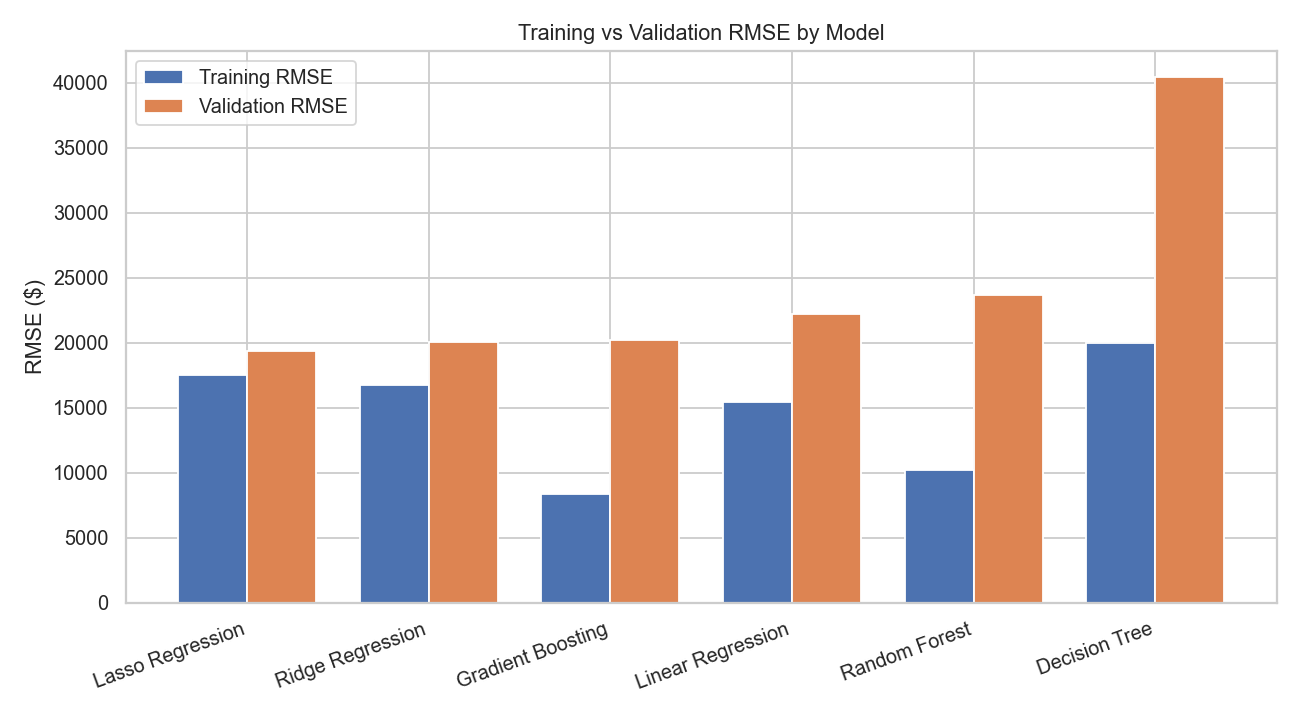

In [72]:
comparison_plot = plot_model_comparison(results_sorted, path=IMAGES_DIR / "model_comparison.png")
Image(filename=str(comparison_plot))

**Reading the chart.** The two regularised linear models have the smallest validation RMSE. The single decision tree has a comparatively good training score but the worst validation error, the classic signature of overfitting. Random Forest improves on the single tree but is still behind the linear models. Gradient Boosting fits the training data very closely and does not fully close the gap on validation.

In [73]:
best_name = results_sorted.iloc[0]["model"]
best_val_predictions = predict_prices(fitted_models[best_name], X_val)
best_metrics = regression_metrics(y_val, best_val_predictions)
pd.Series(best_metrics).round(2)

mae     1.388059e+04
mse     3.749455e+08
rmse    1.936351e+04
r2      9.300000e-01
dtype: float64

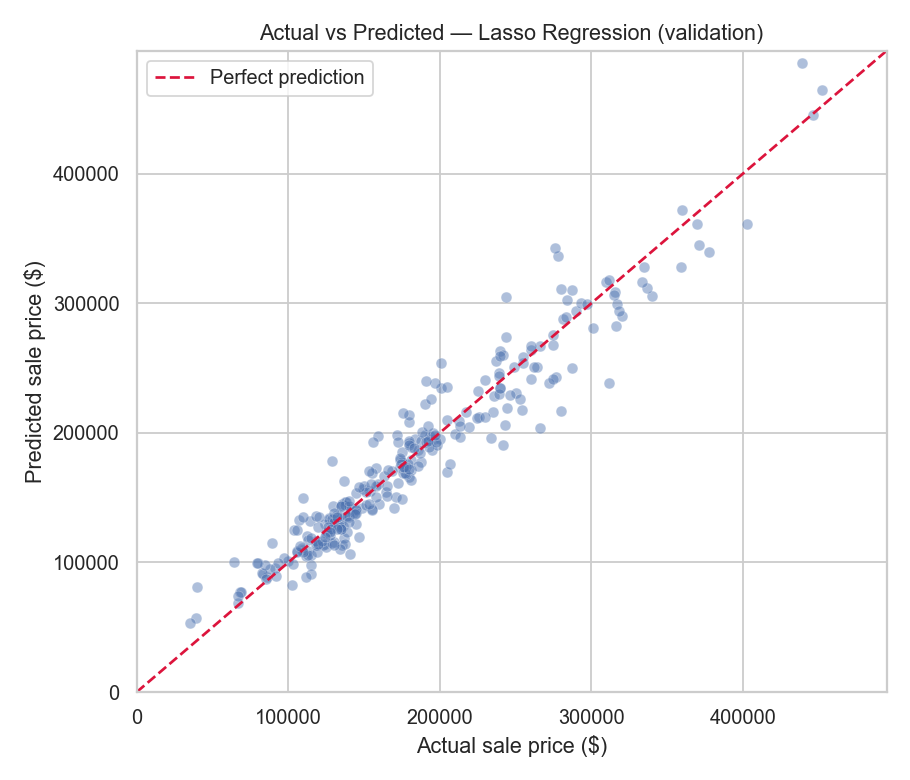

In [74]:
scatter_path = plot_actual_vs_predicted(
    y_val,
    best_val_predictions,
    path=IMAGES_DIR / "eval_actual_vs_predicted.png",
    title=f"Actual vs Predicted — {best_name} (validation)",
)
Image(filename=str(scatter_path))

**Reading the chart.** Points near the dashed line are accurate predictions. The model tracks the main trend well. On average the cheapest homes are slightly over-predicted and the most expensive are slightly under-predicted, but individual errors go both ways — the largest misses reach roughly ±$70k. That shrinkage toward the middle is typical of a regularised linear model fitted on a limited sample and is worth stating as a limitation.

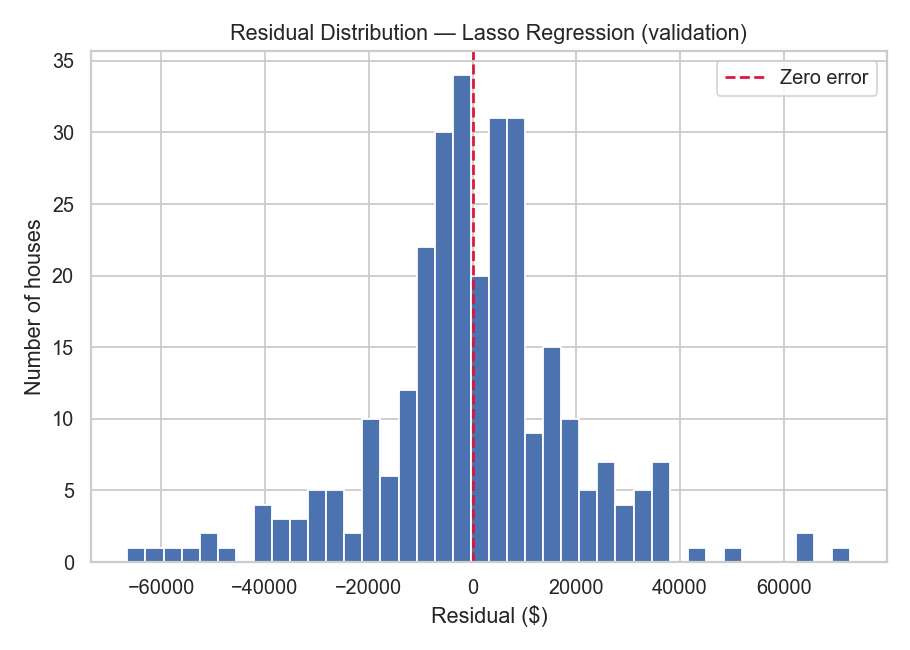

In [75]:
residual_path = plot_residual_distribution(
    y_val,
    best_val_predictions,
    path=IMAGES_DIR / "eval_residual_distribution.png",
    title=f"Residual Distribution — {best_name} (validation)",
)
Image(filename=str(residual_path))

**Reading the chart.** Residuals are centred near zero (skewness about -0.11), so there is no systematic over- or under-pricing overall. The average absolute miss is about $13.9k, and 2.7% of validation houses miss by more than $50k in either direction. A single summary metric such as RMSE hides that spread.

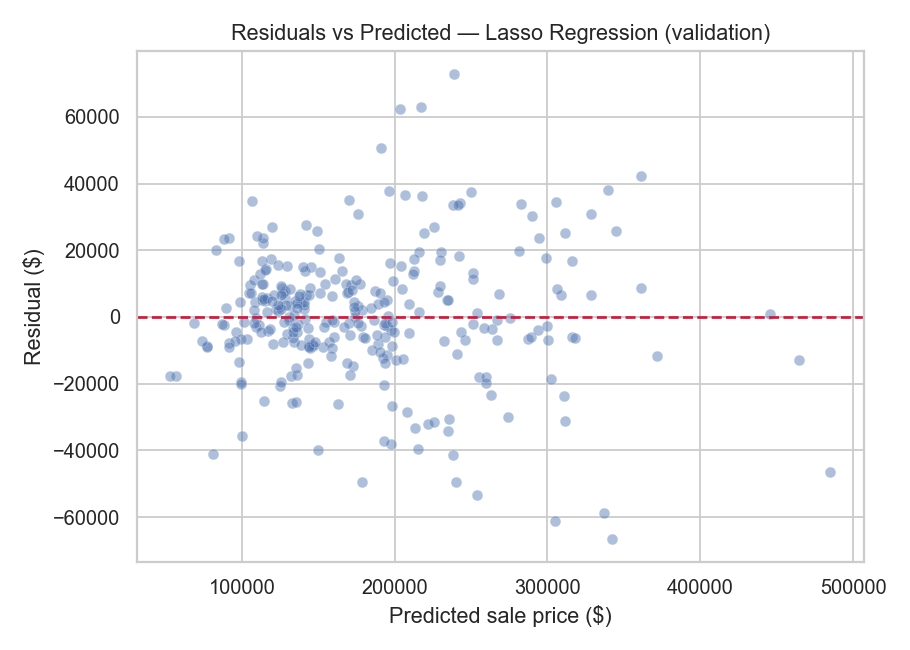

In [76]:
residual_scatter_path = plot_residuals_vs_predicted(
    y_val,
    best_val_predictions,
    path=IMAGES_DIR / "eval_residuals_vs_predicted.png",
    title=f"Residuals vs Predicted — {best_name} (validation)",
)
Image(filename=str(residual_scatter_path))

**Reading the chart.** Ideally residuals form a horizontal band of constant width. Here the band widens with predicted price: mean absolute error is about $10.8k in the cheapest validation quartile and about $21.8k in the most expensive one, and the absolute residual correlates 0.32 with the prediction. Errors are therefore heteroscedastic — expensive houses are harder to pin down in absolute dollars. The log transform reduced this effect but did not eliminate it.

In [77]:
gap = results_sorted.assign(
    rmse_gap=lambda frame: frame["val_rmse"] - frame["train_rmse"],
    gap_percent=lambda frame: (frame["val_rmse"] - frame["train_rmse"]) / frame["train_rmse"] * 100,
)
gap[["model", "train_rmse", "val_rmse", "rmse_gap", "gap_percent"]].round(1)

,model,train_rmse,val_rmse,rmse_gap,gap_percent
0,Lasso Regression,17528.0,19363.5,1835.6,10.5
1,Ridge Regression,16773.7,20031.7,3258.1,19.4
2,Gradient Boosting,8353.1,20241.4,11888.3,142.3
3,Linear Regression,15462.2,22207.1,6744.9,43.6
4,Random Forest,10207.5,23654.9,13447.4,131.7
5,Decision Tree,19970.9,40447.8,20476.9,102.5


##  Final model

The selected pipeline is refitted on **all** labelled training rows (not only the 80% split) and saved as a single artifact, so preprocessing and model travel together.

Refitting on more data is standard once the model choice is fixed: the validation split has already done its job. The saved file is `models/best_model.joblib`.

In [78]:
final_model = train_final_model(X, y, best_name, X_train)
print(f"Selected model: {best_name}")
print(f"Refit on {len(X)} labelled rows")
print(f"Saved to: {PROJECT_ROOT / 'models' / 'best_model.joblib'}")

Selected model: Lasso Regression
Refit on 1458 labelled rows
Saved to: c:\Users\Ayat Ali\Downloads\house-prices-advanced-regression-techniques\models\best_model.joblib


## Prediction demonstration

The competition test set has no `SalePrice`, so there is **no accuracy claim** for these rows. What we can verify is that the full pipeline accepts raw test rows and produces plausible positive prices.

The prediction function applies the same cleaning and feature engineering, then uses the saved pipeline for imputation, encoding, scaling and prediction. Predictions are returned in dollars by converting back from the log scale.

In [79]:
test_df = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "test.csv")
sample_rows = test_df.head(5)

sample_inputs = sample_rows[["Id", "Neighborhood", "GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF"]]
sample_predictions = predict(final_model, sample_rows)

sample_inputs.assign(PredictedSalePrice=sample_predictions["PredictedSalePrice"].round(0))

,Id,Neighborhood,GrLivArea,OverallQual,YearBuilt,TotalBsmtSF,PredictedSalePrice
0,1461,NAmes,896,5,1961,882.0,119803.0
1,1462,NAmes,1329,6,1958,1329.0,150324.0
2,1463,Gilbert,1629,5,1997,928.0,177946.0
3,1464,Gilbert,1604,6,1998,926.0,201936.0
4,1465,StoneBr,1280,8,1992,1280.0,191741.0


In [80]:
reloaded_model = load_model()
reloaded_predictions = predict(reloaded_model, sample_rows)

same_results = np.allclose(
    reloaded_predictions["PredictedSalePrice"].to_numpy(),
    sample_predictions["PredictedSalePrice"].to_numpy(),
)
print(f"Saved artifact reproduces the in-memory predictions: {same_results}")
reloaded_predictions.round(0)

Saved artifact reproduces the in-memory predictions: True


,Id,PredictedSalePrice
0,1461,119803.0
1,1462,150324.0
2,1463,177946.0
3,1464,201936.0
4,1465,191741.0
